In [1]:
import pandas as pd 
import numpy as np 
import polars as pl
from typing import List
from collections import Counter
import glob, os

import matplotlib.pyplot as plt
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats("retina")
from matplotlib.ticker import FuncFormatter
import matplotlib as mpl
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans", "sans-serif"],
    "font.size": 12,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
})


import yaml
with open("../../src/configs.yml", "r") as configs:
    configs = yaml.safe_load(configs)

DATAPATH = configs["SERVER_DATA"]
ROOTPATH = configs["SERVER_WD"]

## load data

In [2]:
# subreddit sets
X0 = 10; N0 = 1
X1 = 20; N1 = 10
X2 = "inf"; N2 = 1
covs1 = "lifetime_d"
covs2 = "lifetime_d_n_post_author_till2019_log"

sets_df = pd.read_csv("../../data-public/subreddit_sets.csv")

subreddit_sets = {
    name: set(group["subreddit"])
    for name, group in sets_df.groupby("set")
}

matched1_indp = subreddit_sets["matched1_indp"]
matched2_indp= subreddit_sets["matched2_indp"]
matched2_conn = subreddit_sets["matched2_conn"]
random = subreddit_sets["random"]
banned = subreddit_sets["banned"]

In [3]:
from src.utils.data_loader_polars import load_filtered_data

years = range(2006, 2020)
cols = ["id","author","subreddit","created_utc"]

def load_post_subreddit(subm_input_fpath, comm_input_fpath, subrs, years=years, cols=cols):
    subm_df = load_filtered_data(years=years, data_dir=subm_input_fpath, filetype="submissions",filter_bots=False).select(cols)
    comm_df = load_filtered_data(years=years, data_dir=comm_input_fpath, filetype="comments",filter_bots=False).select(cols)
    subm_df = subm_df.with_columns(pl.lit("submission").alias("kind"))
    comm_df = comm_df.with_columns(pl.lit("comment").alias("kind"))
    post_df = pl.concat([subm_df, comm_df], how="vertical").filter(pl.col("subreddit").is_in(subrs))
    return post_df

subm_input_banned = f"{DATAPATH}/filtered-data/submissions/subm-from-subr-banned-2020/" 
comm_input_banned = f"{DATAPATH}/filtered-data/comments/comm-from-subr-banned-2020/" 
subm_input_matched1_indp = f"{DATAPATH}/filtered-data/submissions/subm-from-subr-banned-2020-subset3274-match-{covs1}-X{X0}N{N0}/" 
comm_input_matched1_indp = f"{DATAPATH}/filtered-data/comments/comm-from-subr-banned-2020-subset3274-match-{covs1}-X{X0}N{N0}/" 
subm_input_matched2_indp = f"{DATAPATH}/filtered-data/submissions/subm-from-subr-banned-2020-subset3274-match-{covs2}-X{X1}N{N1}/" 
comm_input_matched2_indp = f"{DATAPATH}/filtered-data/comments/comm-from-subr-banned-2020-subset3274-match-{covs2}-X{X1}N{N1}/" 
subm_input_matched2_conn = f"{DATAPATH}/filtered-data/submissions/subm-from-subr-banned-2020-subset3274-match-{covs2}-X{X2}N{N2}/" 
comm_input_matched2_conn = f"{DATAPATH}/filtered-data/comments/comm-from-subr-banned-2020-subset3274-match-{covs2}-X{X2}N{N2}/" 
subm_input_random = f"{DATAPATH}/filtered-data/submissions/subm-from-subr-banned-2020-subset3274-random/" 
comm_input_random = f"{DATAPATH}/filtered-data/comments/comm-from-subr-banned-2020-subset3274-random/" 

post_banned = load_post_subreddit(subm_input_banned, comm_input_banned, banned)
post_matched1_indp = load_post_subreddit(subm_input_matched1_indp, comm_input_matched1_indp, matched1_indp)
post_matched2_indp = load_post_subreddit(subm_input_matched2_indp, comm_input_matched2_indp, matched2_indp)
post_matched2_conn = load_post_subreddit(subm_input_matched2_conn, comm_input_matched2_conn, matched2_conn)
post_random = load_post_subreddit(subm_input_random, comm_input_random, random)


******************
Loading Submissions from /cinddata/reddit-ban-study/filtered-data/submissions/subm-from-subr-banned-2020/...
	loading: 2006
	loading: 2007
	loading: 2008
	loading: 2009
	loading: 2010
	loading: 2011
	loading: 2012
	loading: 2013
	loading: 2014
	loading: 2015
	loading: 2016
	loading: 2017
	loading: 2018
	loading: 2019
******************
Loading Comments from /cinddata/reddit-ban-study/filtered-data/comments/comm-from-subr-banned-2020/...
	loading: 2006
	loading: 2007
	loading: 2008
	loading: 2009
	loading: 2010
	loading: 2011
	loading: 2012
	loading: 2013
	loading: 2014
	loading: 2015
	loading: 2016
	loading: 2017
	loading: 2018
	loading: 2019
******************
Loading Submissions from /cinddata/reddit-ban-study/filtered-data/submissions/subm-from-subr-banned-2020-subset3274-match-lifetime_d-X10N1/...
	loading: 2006
	loading: 2007
	loading: 2008
	loading: 2009
	loading: 2010
	loading: 2011
	loading: 2012
	loading: 2013
	loading: 2014
	loading: 2015
	loading: 2016
	lo

## load toxicity output

In [4]:
input_dir = f"{DATAPATH}/output/toxicity/subset3274/detoxify-multilingual-all-subm-perweek/"

results_banned = pl.read_parquet(f"{input_dir}subm-comm-from-subr-banned-2020-by-subm-toxicity.parquet")
results_matched1_indp = pl.read_parquet(f"{input_dir}subm-comm-from-subr-banned-2020-subset3274-match-{covs1}-X{X0}N{N0}-by-subm-toxicity.parquet")
results_matched2_indp = pl.read_parquet(f"{input_dir}subm-comm-from-subr-banned-2020-subset3274-match-{covs2}-X{X1}N{N1}-by-subm-toxicity.parquet")
results_matched2_conn = pl.read_parquet(f"{input_dir}subm-comm-from-subr-banned-2020-subset3274-match-{covs2}-X{X2}N{N2}-by-subm-toxicity.parquet")
results_random = pl.read_parquet(f"{input_dir}subm-comm-from-subr-banned-2020-subset3274-random-by-subm-toxicity.parquet")


clean_text_dir = f"{DATAPATH}/filtered-data/subm_comm_clean/"
cleaned_text_banned = pl.read_parquet(f"{clean_text_dir}subm-comm-from-subr-banned-2020-aggr-by-subm-2006-2019.parquet")
cleaned_text_matched1_indp = pl.read_parquet(f"{clean_text_dir}subm-comm-from-subr-banned-2020-subset3274-match-{covs1}-X{X0}N{N0}-aggr-by-subm-2006-2019.parquet")
cleaned_text_matched2_indp = pl.read_parquet(f"{clean_text_dir}subm-comm-from-subr-banned-2020-subset3274-match-{covs2}-X{X1}N{N1}-aggr-by-subm-2006-2019.parquet")
cleaned_text_matched2_conn = pl.read_parquet(f"{clean_text_dir}subm-comm-from-subr-banned-2020-subset3274-match-{covs2}-X{X2}N{N2}-aggr-by-subm-2006-2019.parquet")
cleaned_text_random = pl.read_parquet(f"{clean_text_dir}subm-comm-from-subr-banned-2020-subset3274-random-aggr-by-subm-2006-2019.parquet")

In [5]:
results_banned

id,toxicity,severe_toxicity,obscene,threat,insult,identity_attack
str,f64,f64,f64,f64,f64,f64
"""100315""",0.092224,0.000037,0.000634,0.000536,0.054291,0.000376
"""1003oj""",0.000287,0.000093,0.000629,0.000079,0.000634,0.000222
"""1003tf""",0.000724,0.000057,0.000462,0.000112,0.000443,0.000163
"""1006nn""",0.079468,0.000166,0.003376,0.005081,0.005959,0.000379
"""1007le""",0.267334,0.001255,0.046295,0.001755,0.016098,0.0047
…,…,…,…,…,…,…
"""zzppx""",0.071472,0.000161,0.002115,0.000122,0.008919,0.006668
"""zzqe4""",0.000627,0.000026,0.000177,0.000043,0.000305,0.000106
"""zzsd""",0.000351,0.007347,0.044586,0.002684,0.037262,0.008125


In [6]:
from scipy.stats import t

styles = {
    "banned":         dict(color="darkred",    linestyle="-"),
    "matched1_indp": dict(color="steelblue",  linestyle="--"),
    "matched2_indp": dict(color="darkgreen",  linestyle="--"),
    "matched2_conn": dict(color="darkorange", linestyle="-."),
    "random":        dict(color="grey",       linestyle=":"),
}

labels = {
    "banned": r"$B$",
    "matched1_indp": r"$M_{\mathrm{indp},1}$",
    "matched2_indp": r"$M_{\mathrm{indp},2}$",
    "matched2_conn": r"$M_{\mathrm{conn},2}$",
    "random": r"$U$",
}

results = {
    "banned": results_banned,
    "matched1_indp": results_matched1_indp,
    "matched2_indp": results_matched2_indp,
    "matched2_conn": results_matched2_conn,
    "random": results_random,
}

cleaned_text = {
    "banned": cleaned_text_banned,
    "matched1_indp": cleaned_text_matched1_indp,
    "matched2_indp": cleaned_text_matched2_indp,
    "matched2_conn": cleaned_text_matched2_conn,
    "random": cleaned_text_random,
}

posts = {
    "banned": post_banned,
    "matched1_indp": post_matched1_indp,
    "matched2_indp": post_matched2_indp,
    "matched2_conn": post_matched2_conn,
    "random": post_random,
}


## plot out temporal trends with weekly samples

In [7]:
posts_subm = {
    group: df.filter(pl.col("kind") == "submission")
    for group, df in posts.items()
}

def sample_submissions_per_subreddit_week(
    subm: pl.DataFrame,
    window_length: str = "1w",
    n: int = 20,
    seed: int = 42,
) -> pl.DataFrame:
    sample = (
        subm
        .with_columns(
            pl.col("created_utc")
              .cast(pl.Datetime)
              .dt.truncate(window_length)
              .alias("week")
        )
        .with_columns(
            pl.int_range(pl.len(), dtype=pl.UInt32)
              .shuffle(seed=seed)
              .over(["subreddit", "week"])
              .alias("_rank")
        )
        .filter(pl.col("_rank") < n)
        .drop("_rank")
    )

    return sample

def merge_toxicity_text_time(
    results_df: pl.DataFrame,
    cleaned_df: pl.DataFrame,
    post_df: pl.DataFrame,
    n_sample: int = None,
    seed: int = 42,
    window_length: str = "1w",
) -> pl.DataFrame:

    post_meta = (
        post_df
        .select(["id", "created_utc", "subreddit"])
        .unique("id")
    )

    df = (
        results_df
        .join(cleaned_df, on="id", how="left")
        .join(post_meta, on="id", how="left")
    )

    if n_sample is not None:
        sample = sample_submissions_per_subreddit_week(
            post_meta,
            window_length=window_length,
            n=n_sample,
            seed=seed,
        )
        
        sample_ids = sample.select("id").unique()

        df = df.join(
            sample_ids,
            on="id",
            how="semi",
        )

    return df

# Create merged toxicity dataframes for all five groups

n_sample = 50  # set to None if you do not want weekly sampling

toxicity_dfs = {
    group: merge_toxicity_text_time(
        results_df=results[group],
        cleaned_df=cleaned_text[group],
        post_df=posts_subm[group],
        n_sample=n_sample,
        seed=42,
        window_length="1w",
    )
    for group in results.keys()
}

In [8]:
score_summary = pl.DataFrame([
    {
        "Set": labels[group],
        "Scored submissions": results[group]["id"].n_unique(),
        "Retained after sampling": toxicity_dfs[group]["id"].n_unique(),
    }
    for group in results
])

score_summary

Set,Scored submissions,Retained after sampling
str,i64,i64
"""$B$""",9391552,1510963
"""$M_{\mathrm{indp},1}$""",258934,220189
"""$M_{\mathrm{indp},2}$""",1373355,1018333
"""$M_{\mathrm{conn},2}$""",2207508,1262829
"""$U$""",18021951,4535037


In [9]:
def time_mean_ci(
    df: pl.DataFrame,
    value_col: str = "toxicity",
    time_col: str = "created_utc",
    freq: str = "W",
) -> pd.DataFrame:

    pdf = df.to_pandas()
    pdf[time_col] = pd.to_datetime(pdf[time_col])

    pdf = pdf.dropna(subset=[time_col, value_col])

    out = (
        pdf
        .set_index(time_col)
        .resample(freq)
        .agg(
            mean=(value_col, "mean"),
            median=(value_col, "median"),
            std=(value_col, "std"),
            n=(value_col, "count"),
        )
        .reset_index()
    )

    out["se"] = out["std"] / np.sqrt(out["n"])

    out["tcrit"] = out["n"].apply(
        lambda x: t.ppf(0.975, df=x - 1) if x > 1 else np.nan
    )

    out["ci_low"] = out["mean"] - out["tcrit"] * out["se"]
    out["ci_high"] = out["mean"] + out["tcrit"] * out["se"]

    return out


def plot_toxicity_trends(
    toxicity_dfs: dict,
    var: str = "toxicity",
    stat: str = "mean",       # "mean" or "median"
    freq: str = "W",
    fill_ci: bool = True,
    ylim: None = (-0.02, 0.72),
    figsize: tuple = (13.4,3.4),
    savepath: None = None,
):

    fig, ax = plt.subplots(figsize=figsize)

    for group, df in toxicity_dfs.items():

        aggr = time_mean_ci(
            df,
            value_col=var,
            time_col="created_utc",
            freq=freq,
        )

        style = styles[group]
        ycol = "mean" if stat == "mean" else "median"

        ax.plot(
            aggr["created_utc"],
            aggr[ycol],
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=2.2 if group == "banned" else 1.8,
            label=labels[group],
        )

        if fill_ci and stat == "mean":
            ax.fill_between(
                aggr["created_utc"],
                aggr["ci_low"],
                aggr["ci_high"],
                color=style["color"],
                alpha=0.18 if group == "banned" else 0.12,
                linewidth=0,
            )

    ax.legend(frameon=False, fontsize=9, loc=1)

    ax.set_ylabel(
        f"average {var.replace('_', ' ')}",
        fontsize=13,
    )

    ax.set_title(
        # f"Temporal trends of {stat} {var.replace('_', ' ')}",
        f"Average toxicity across subreddits\n(metric: {var})",
        fontsize=14,
    )

    if ylim is not None:
        ax.set_ylim(*ylim)

    ax.spines[["top", "right"]].set_visible(False)

    # fig.autofmt_xdate()

    if savepath is not None:
        fig.savefig(savepath, dpi=300, bbox_inches="tight")

    return fig, ax


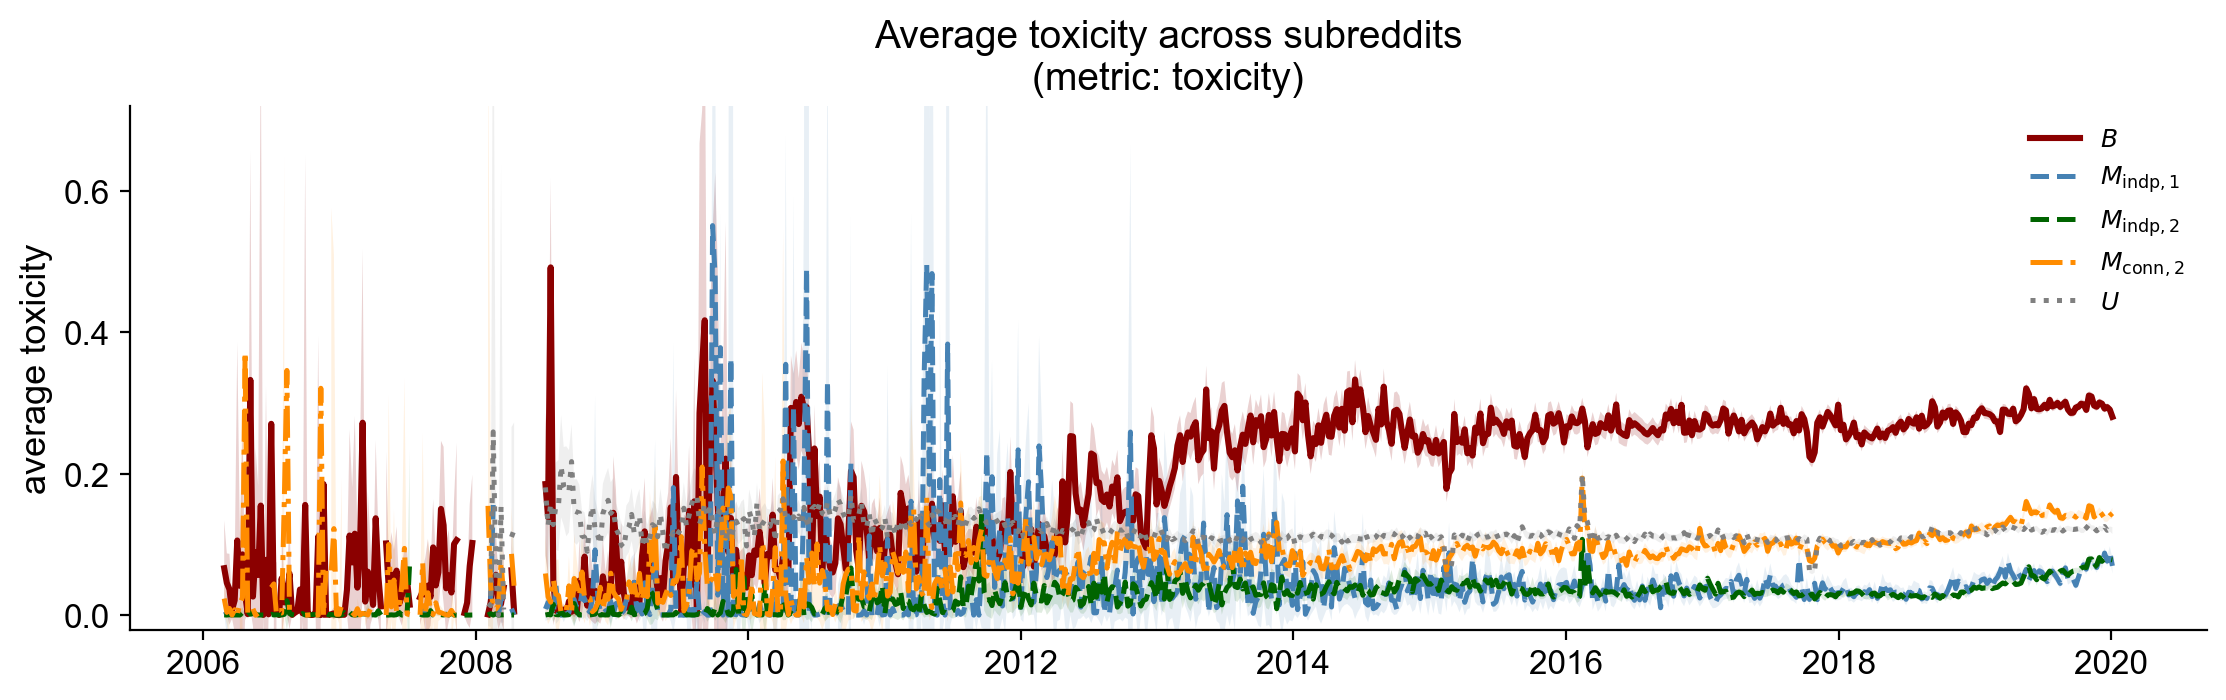

In [10]:
var = "toxicity"

fig, ax = plot_toxicity_trends(
    toxicity_dfs=toxicity_dfs,
    var=var,
    stat="mean",
    freq="W",
    fill_ci=True,
    ylim=(-0.02, 0.72),
    # savepath=f"../../../../output/260615-output-remote/{var}-weekly-five-groups-{n_sample}subm-per-week.pdf",
)

# plt.savefig("../../output/mainbody/mean_toxicity_2006_2019_5groups.png", dpi=300, bbox_inches="tight")
# plt.savefig("../../output/mainbody/mean_toxicity_2006_2019_5groups.pdf", dpi=300, bbox_inches="tight")

## for appendix, plot out different toxicity metrics, with the same five groups of subreddits

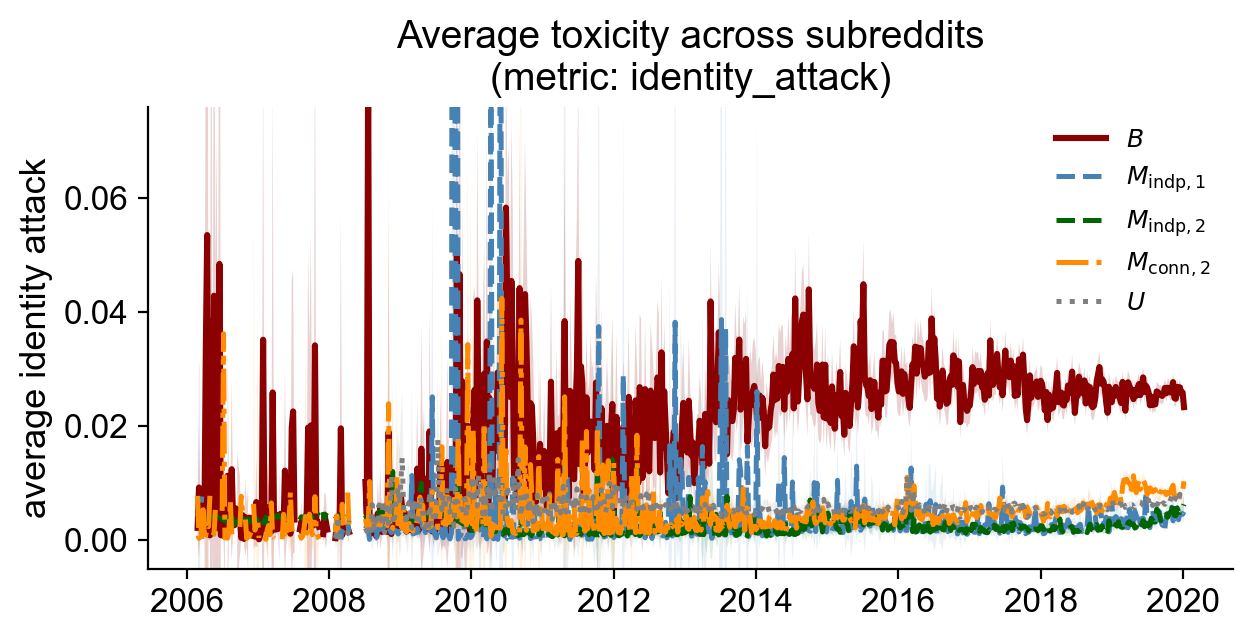

In [11]:
# var = "severe_toxicity"     # ylim=(-0.005, 0.065),
# var = "obscene"             # ylim=(-0.02, 0.5),
# var = "threat"              # ylim=(-0.005, 0.065),
# var = "insult"              # ylim=(-0.02, 0.21),
var = "identity_attack"

fig, ax = plot_toxicity_trends(
    toxicity_dfs=toxicity_dfs,
    var=var,
    stat="mean",
    freq="W",
    fill_ci=True,
    ylim=(-0.005, 0.076),
    figsize=(7,3),
    # savepath=f"../../../../output/260615-output-remote/{var}-weekly-five-groups-{n_sample}subm-per-week.pdf",
)

# plt.savefig(f"../../output/appendix/mean_{var}_2006_2019_5groups.png", dpi=300, bbox_inches="tight")
# plt.savefig(f"../../output/appendix/mean_{var}_2006_2019_5groups.pdf", dpi=300, bbox_inches="tight")